<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography example legend</div>
    </div>
</div>



In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

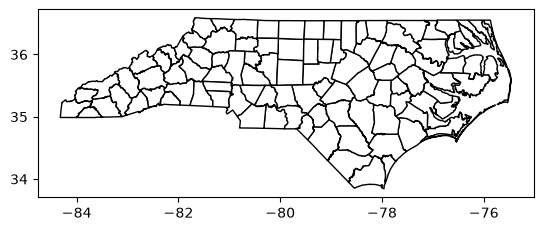

In [2]:


# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

<Axes: >

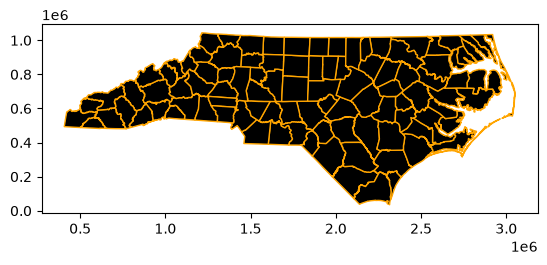

In [6]:
ncc = nc_counties.to_crs(epsg="6543").copy()
ncc.plot(edgecolor="orange", facecolor="black")


In [ ]:
# making the above plot code into a function
# def ncplot(ax): #ax is the paramenter
#     ncc.plot(ax=ax, edgecolor="orange", facecolor="black")

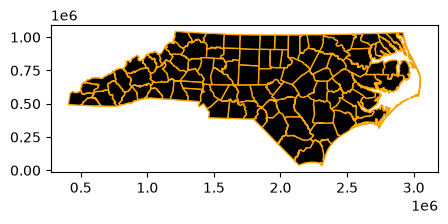

In [ ]:
# fig, ax = plt.subplots(figsize=(5,10))
# ncplot(ax)
# plt.show()

In [23]:
# another way to write a function for the plot
def ncplot(ax,stroke,fill):
    ncc.plot(ax=ax, edgecolor=stroke, facecolor=fill)

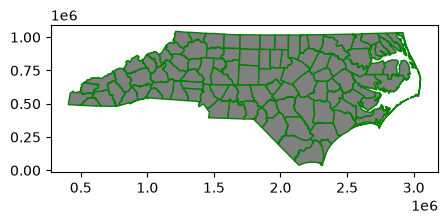

In [24]:
fig, ax = plt.subplots(figsize=(5,10))
ncplot(ax, "green", "gray")
plt.show()

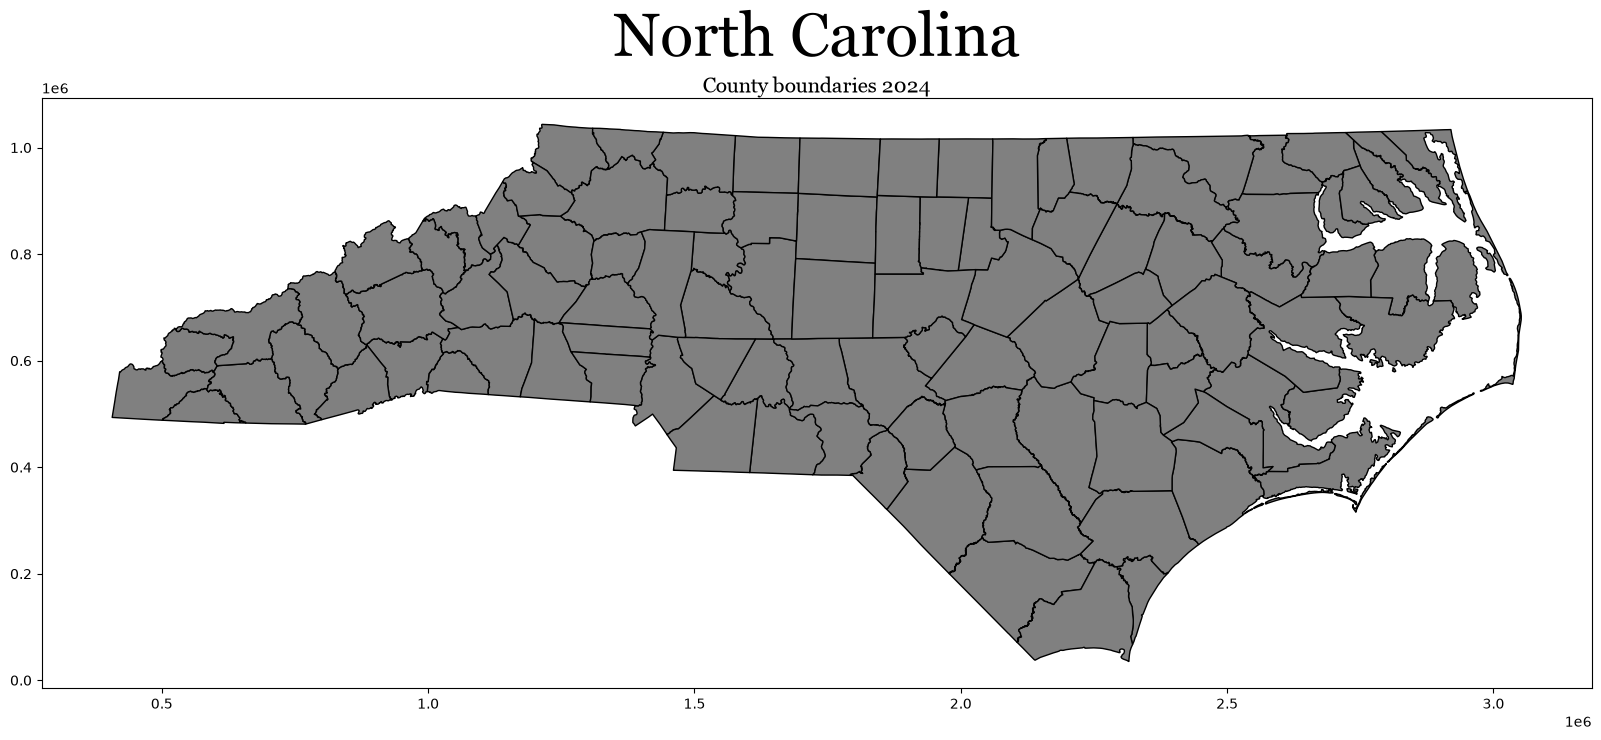

In [34]:
fig, ax = plt.subplots(figsize=(20,10))
ncplot(ax, "black", "grey")
ax.set_title("North Carolina", fontsize=44, pad=30, fontname='Georgia')
ax.text(
    .5, 1.0, "County boundaries 2024", transform=ax.transAxes,ha="center", va="bottom", fontsize="15", fontname="Georgia"
)
plt.show()

In [37]:
ncc_copy = ncc.copy()
ncc_copy["geometry"] = ncc_copy.geometry.centroid
ncc_copy["geometry"].head
ncc_copy[ncc_copy["NAME"]=="Durham"]["geometry"]

1931    POINT (2036476.502 831990.237)
Name: geometry, dtype: geometry

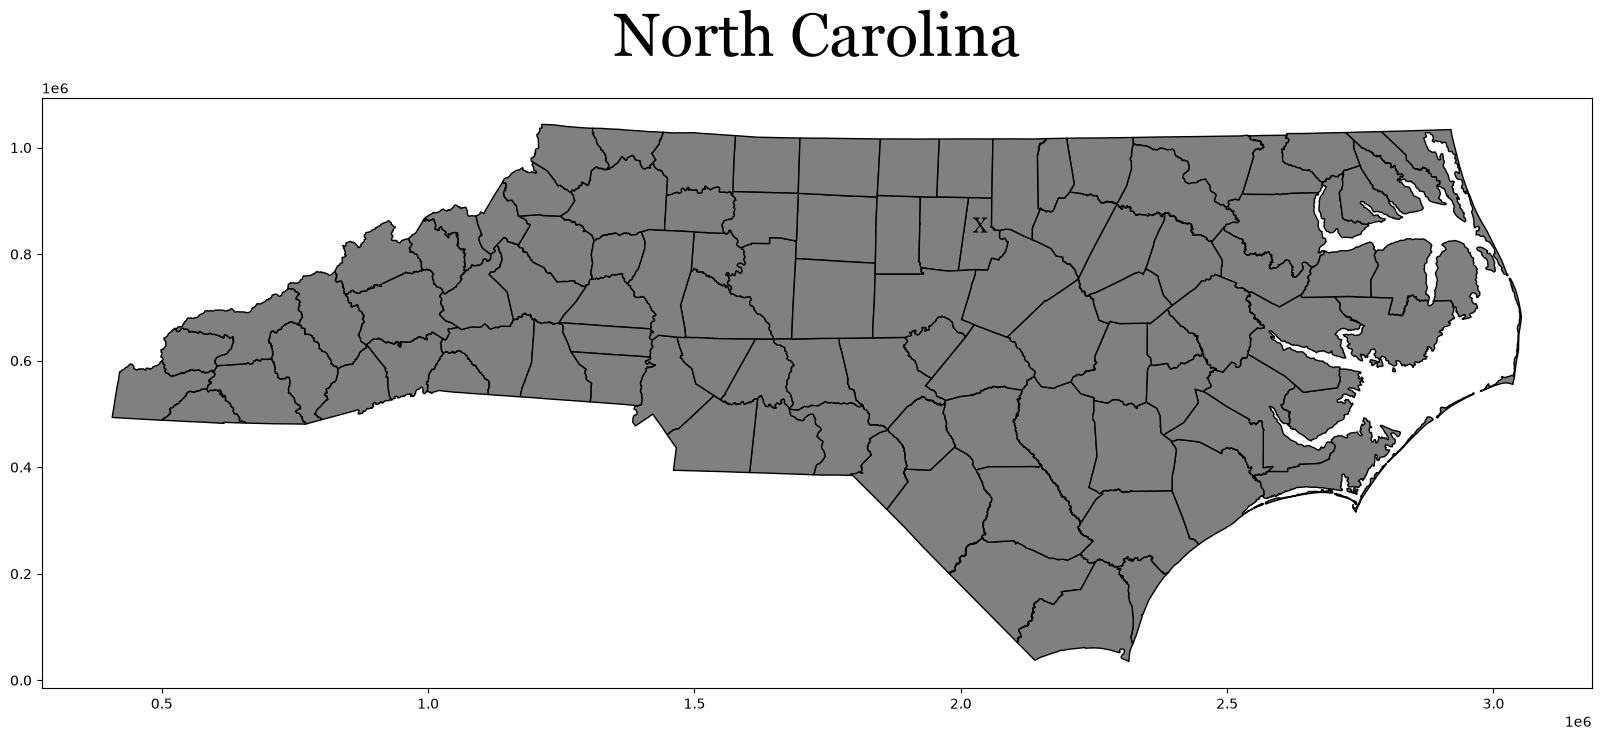

In [ ]:
# putting a label over Durham with the geometry of the point from Durham from above
fig, ax = plt.subplots(figsize=(20,10))
ncplot(ax, "black", "grey")
ax.set_title("North Carolina", fontsize=44, pad=30, fontname='Georgia')
ax.text(
    2036476.502, 831990.237, "X", ha="center", va="bottom", fontsize="15", fontname="Georgia"
)
plt.show()

In [ ]:
# code the labels of each of the counties in a centroid, assign it the county name
# it will look messy, but make it a small font size 
# you could make the size of the county name be proportional for the size of population
# make it in a loop, assign the x and y. in each row, have brack for x and y and the row y
# for row in rows, ax.text point[x], point[y], name

In [42]:
ncc_copy.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
90,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,POINT (2104249.345 187867.293)
91,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,POINT (486772.115 542262.558)
92,37,149,01008579,0500000US37149,37149,Polk,Polk County,NC,North Carolina,06,615606325,1964035,POINT (1054205.576 571670.468)
93,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,POINT (1264466.338 986177.558)
94,37,055,01026133,0500000US37055,37055,Dare,Dare County,NC,North Carolina,06,992558552,3000513281,POINT (2949355.035 754887.689)


In [45]:
for name in ncc_copy["NAME"]:
    point = ncc_copy["geometry"][ncc_copy["NAME"]==name]
    print(name)
    print(point.geometry.x)
    print(point.geometry.y)

Columbus
90    2.104249e+06
dtype: float64
90    187867.292901
dtype: float64
Cherokee
91    486772.114791
dtype: float64
91    542262.557899
dtype: float64
Polk
92    1.054206e+06
dtype: float64
92    571670.467897
dtype: float64
Ashe
93    1.264466e+06
dtype: float64
93    986177.557595
dtype: float64
Dare
94    2.949355e+06
dtype: float64
94    754887.688612
dtype: float64
Hertford
95    2.594241e+06
dtype: float64
95    955648.762878
dtype: float64
Wilkes
217    1.361864e+06
dtype: float64
217    900902.102395
dtype: float64
Rowan
218    1.547023e+06
dtype: float64
218    691123.075165
dtype: float64
Henderson
219    962362.268166
dtype: float64
219    595501.294952
dtype: float64
Sampson
220    2.188318e+06
dtype: float64
220    452363.029288
dtype: float64
Mitchell
221    1.064542e+06
dtype: float64
221    838626.851278
dtype: float64
Stanly
343    1.626795e+06
dtype: float64
343    570774.938152
dtype: float64
Anson
344    1.669692e+06
dtype: float64
344    447213.669796
dtype: 